# CBFE-ARX on the two-link arm

This notebook runs the constrained Bethe free energy agent on a Bayesian ARX model (`agents/cbfe_arx`) on the arm of `envs/robot_arm.py`, with and without the information constraint. The agent regresses the next output on the current input and the previous output through a fixed feature map,

$$y_k \sim \mathcal{N}\big(A^\top \phi(u_k, y_{k-1}),\, W^{-1}\big),$$

and keeps a matrix-normal Wishart posterior over $(A, W)$, which it updates in closed form after every step. Its policy at each step is the MAP of

$$q^*(u) \propto p(u)\, \big(1 + \ell(u)\big)^{\beta D_y / 2} \exp\Big(-\mathbb{E}_{p(y \mid u, \mathcal{D})}\big[-\ln p_*(y)\big]\Big),$$

where $p(u)$ is a symmetric Beta prior on $[-1, 1]^2$, $\ell(u)$ the leverage of the input, and $(D_y/2)\ln(1+\ell)$ the input-dependent part of the parameter information $I(\Theta; y \mid u)$. The multiplier $\beta \geq 0$ belongs to the information constraint $I(\Theta; y \mid u) \geq -H[p_*]$:

- **without the constraint**, $\beta = 0$ (`fixed_beta=0`);
- **with the constraint**, $\beta$ follows from the KKT conditions at every step (`fixed_beta=None`): zero if the floor is met, the root of $I = -H[p_*]$ if it can be met, and $\beta_{\max}$ otherwise.

`experiment-arm/reaching.py` holds the protocol. Three of its choices follow from the ARX model class and are explained there: the agent observes joint angles from encoders (0.001 rad) and forms $y = (q, \dot q)$ with a finite-difference velocity; it acts every 0.1 s; and its prior comes from a nominal simulator of the arm with $\theta$ at the prior mean, tempered to the confidence of a few hundred observations. The end-effector targets become joint-space goals through inverse kinematics.

1. Settings
2. The informative prior
3. One episode with and without the information constraint
4. Why the multiplier saturates
5. The goal width moves the multiplier through its regimes
6. Eight noise seeds
7. Playground
8. Takeaways

In [1]:
import os
for var in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ.setdefault(var, '1')      # tiny matrices: threading only adds overhead

import sys
import time
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'envs' / 'robot_arm.py').exists())
for path in (REPO_ROOT, REPO_ROOT / 'experiment-arm'):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from envs.robot_arm import ArmModel, ArmParams, RobotArm, PARAM_UNITS, forward_kinematics
from envs.robot_arm_viz import animate_arm, draw_arm, plot_workspace
import reaching as R

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
VARIANTS = {'without constraint (β = 0)': 0.0, 'with constraint (KKT β)': None}
COLORS = dict(zip(VARIANTS, ('C0', 'C3')))

## 1. Settings

`R.Settings` collects everything that defines the agent except $\beta$. Edit the cell to change the goal widths, the planner or the prior. The plant's true parameters and the controller's nominal parameters are those of `simulate_arm.ipynb`: the nominal values sit one prior standard deviation below the truth.

This notebook documents the first study and pins its settings (`R.FIRST_STUDY`: goal widths 0.02 rad and 0.2 rad/s, prior weight 0.3, torque limit 2 N m, horizon 5 steps, one RK4 substep). The defaults of `reaching.py` have since changed: the goal variances are halved, the prior variance of the ARX coefficients is doubled, and the torque limit and the horizon are doubled (`cbfe_arx_payload.ipynb`).

In [2]:
s = R.FIRST_STUDY                                    # settings of the first study
truth = ArmParams()
nominal = ArmModel(truth, R.ARM_CONFIG).params      # θ at the prior mean

print(f"{'parameter':>10} {'true':>7} {'nominal':>8}  unit")
for name in ('m_p', 'd1', 'd2'):
    print(f"{name:>10} {getattr(truth, name):7.3f} {getattr(nominal, name):8.3f}  {PARAM_UNITS[name]}")
print()
for key, val in vars(s).items():
    print(f'{key:>18} = {val}')
print(f'{"control period":>18} = {s.dt} s, {s.steps_per_target} steps per target')
print(f'{"floor -H[p_*]":>18} = {R.joint_goal(np.zeros(2), s).negative_entropy():.2f} nats')

 parameter    true  nominal  unit
       m_p   0.500    0.350  kg
        d1   0.200    0.150  N m s/rad
        d2   0.200    0.150  N m s/rad

          substeps = 2
seconds_per_target = 3.0
             u_max = 2.0
      rk4_substeps = 1
           pos_std = 0.02
           vel_std = 0.2
           horizon = 5
           n_iters = 2
           N_basis = 1
           L_basis = (1.0, 1.0, 3.141592653589793, 3.141592653589793, 6.0, 6.0)
     Lambda0_scale = 0.1
      Omega0_scale = 0.1
      beta_prior_a = 2.0
          beta_max = 50.0
       prior_steps = 600
      prior_weight = 0.3
        prior_seed = 0
    control period = 0.1 s, 30 steps per target
     floor -H[p_*] = 5.37 nats


## 2. The informative prior

The prior is the matrix-normal Wishart posterior after 600 steps of closed-loop excitation of the nominal arm, with each step counted with weight 0.3. The cell compares the one-step prediction error of this prior and of the uninformed prior on fresh excitation data from the nominal arm and from the true arm. The noise floor of the finite-difference velocity is $\sqrt{2}\cdot 0.001 / 0.1 \approx 0.014$ rad/s.

In [3]:
from agents.common import MultivariateNormal

goal0 = R.joint_goal(R.joint_targets()[0], s)
informed = R.build_agent(s, 0.0, nominal, goal0)
uninformed = R.build_agent(replace(s, prior_weight=0.0), 0.0, nominal, goal0)

def one_step_rmse(agent, params, seed):
    X, Y = R.nominal_data(replace(s, prior_seed=seed), params)
    pred = np.array([agent.estimator.posterior.posterior_predictive(agent.estimator.feature_map(x)).mean for x in X])
    return np.sqrt(np.mean((pred - Y)**2, axis=0))

rows = []
for label, agent in (('uninformed prior', uninformed), ('informative prior', informed)):
    for arm, params in (('nominal arm', nominal), ('true arm', truth)):
        rmse = one_step_rmse(agent, params, seed=7)
        rows.append({'prior': label, 'data from': arm, 'q1 [rad]': rmse[0], 'q2 [rad]': rmse[1],
                     'v1 [rad/s]': rmse[2], 'v2 [rad/s]': rmse[3]})
pd.DataFrame(rows).round(3)

,prior,data from,q1 [rad],q2 [rad],v1 [rad/s],v2 [rad/s]
0,uninformed prior,nominal arm,1.498,1.821,1.321,1.215
1,uninformed prior,true arm,1.508,1.809,1.275,1.169
2,informative prior,nominal arm,0.022,0.040,0.195,0.351
3,informative prior,true arm,0.021,0.036,0.179,0.310


The uninformed prior of `Agent.build` predicts the next joint angles with errors of 1.5–1.8 rad, and an agent that starts from it reaches none of the targets within 3 s (set the prior weight to 0.01 in the playground to see it). The informative prior cuts the error by a factor of about 50 in angle and 4–7 in velocity. Its error on the true arm (0.021 and 0.036 rad, 0.18 and 0.31 rad/s) is no larger than on the nominal arm, because the ARX model cannot represent the configuration-dependent inertia and the centripetal torques of the arm. In this formulation, the model-class error therefore dominates the mismatch in the physical parameters, and most of the prior's remaining uncertainty is structural.

## 3. One episode with and without the information constraint

Both agents start from the same informative prior and run the four targets with plant noise seed 0, 3 s per target. A target counts as reached once the true end effector comes within 2 cm of it.

without constraint (β = 0) (1.7 s): reach_time 1.4, reached 1, hold_error 0.928, rms_torque 1.08, beta_mean 0, active 0, info_gain 0.149, surprise -3.78, pred_rmse 0.22, response_ratio 0.84


with constraint (KKT β) (2.1 s): reach_time 1.4, reached 1, hold_error 1.48, rms_torque 1.17, beta_mean 50, active 1, info_gain 0.15, surprise -3.81, pred_rmse 0.224, response_ratio 0.912


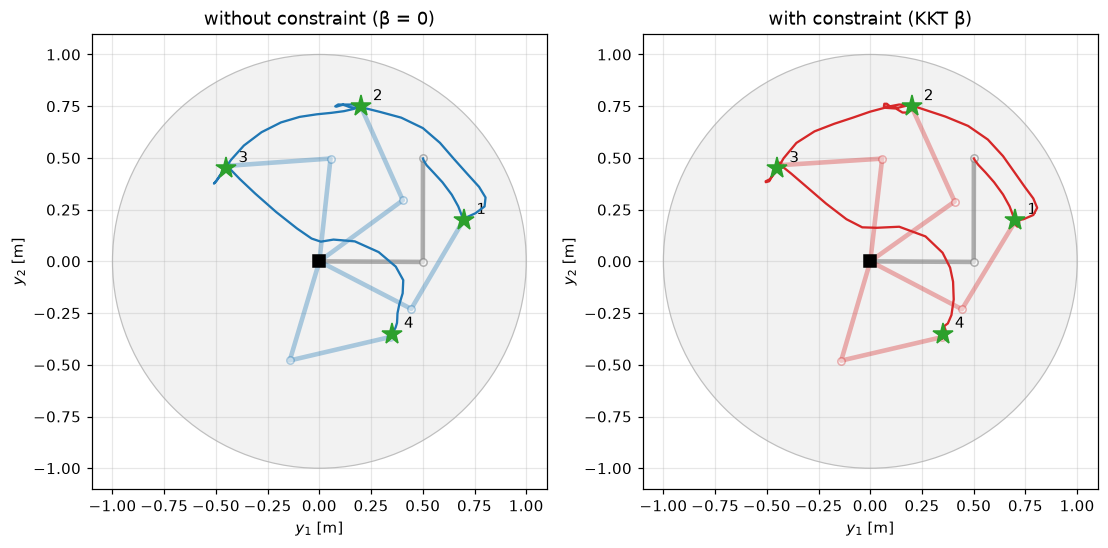

In [4]:
episodes = {}
for label, fixed_beta in VARIANTS.items():
    t0 = time.perf_counter()
    episodes[label] = R.run_seed(fixed_beta, seed=0, s=s, truth=truth)
    scores = R.summarise(episodes[label], s)
    print(f'{label} ({time.perf_counter() - t0:.1f} s): ' + ', '.join(f'{k} {v:.3g}' for k, v in scores.items()))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.8), layout='constrained')
for ax, (label, ep) in zip(axs, episodes.items()):
    plot_workspace(ax, truth)
    draw_arm(ax, ep.xs[0, :2], truth, color='0.5', alpha=0.6, lw=3)
    for i, target in enumerate(R.TARGETS):
        draw_arm(ax, ep.xs[(i + 1) * s.steps_per_target, :2], truth, color=COLORS[label], alpha=0.35, lw=3)
        ax.plot(*target, '*', color='C2', ms=14, zorder=5)
        ax.annotate(str(i + 1), target, textcoords='offset points', xytext=(8, 4))
    ax.plot(*ep.ee.T, color=COLORS[label], lw=1.5, zorder=4)
    ax.set_title(label)
plt.show()

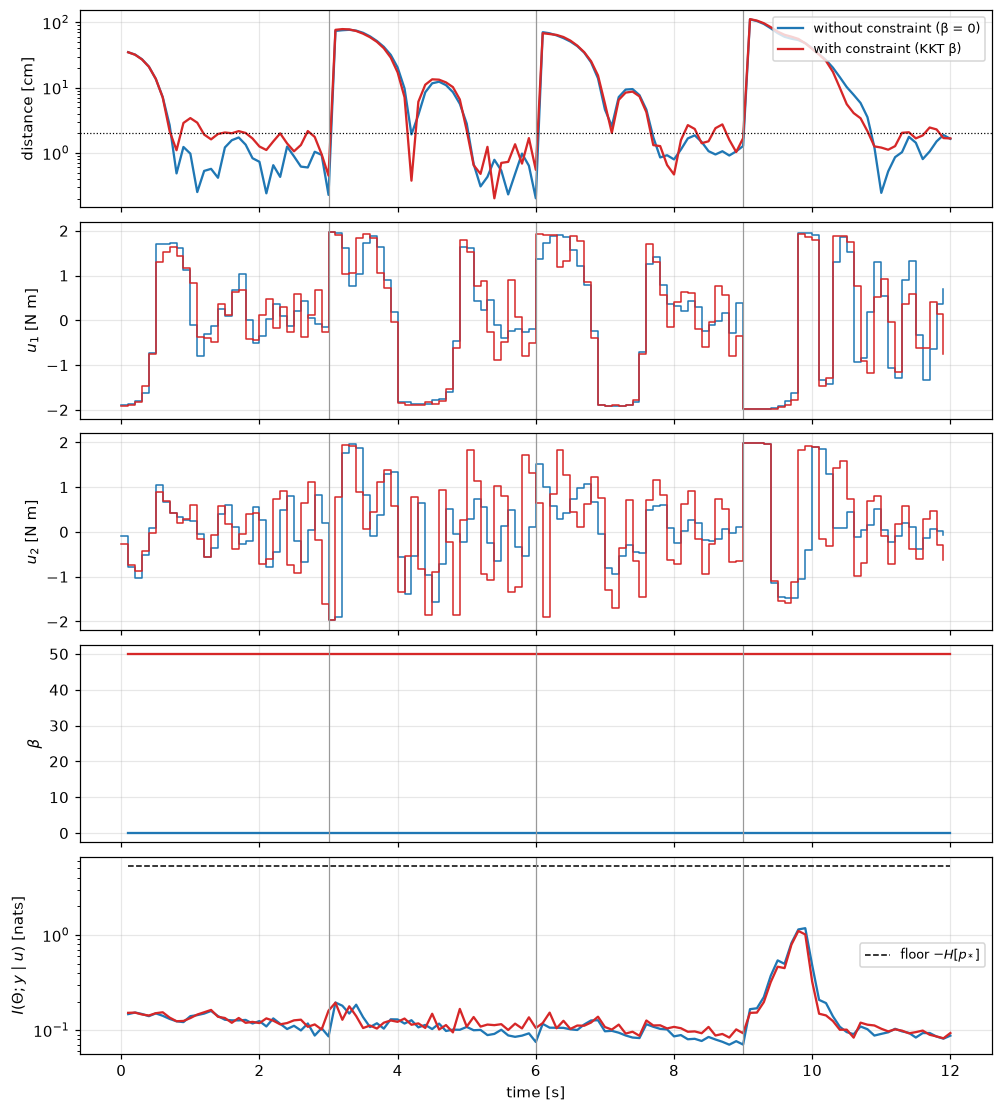

In [5]:
fig, axs = plt.subplots(5, 1, figsize=(9, 10), sharex=True, layout='constrained')
for label, ep in episodes.items():
    c = COLORS[label]
    t = np.arange(1, len(ep.actions) + 1) * ep.dt
    axs[0].plot(t, 100 * ep.distance, color=c, label=label)
    for j in range(2):
        axs[1 + j].step(t - ep.dt, ep.torques[:, j], where='post', color=c, lw=1)
    axs[3].plot(t, ep.beta, color=c)
    axs[4].plot(t, ep.info, color=c)
axs[4].plot(t, episodes[label].floor, 'k--', lw=1, label=r'floor $-H[p_*]$')
axs[0].axhline(100 * R.REACH_TOL, color='k', lw=0.8, ls=':')
axs[0].set(yscale='log', ylabel='distance [cm]')
axs[0].legend(fontsize='small', loc='upper right')
for j in range(2):
    axs[1 + j].set(ylabel=f'$u_{j + 1}$ [N m]', ylim=(-2.2, 2.2))
axs[3].set(ylabel=r'$\beta$')
axs[4].set(ylabel=r'$I(\Theta; y \mid u)$ [nats]', yscale='log')
axs[4].legend(fontsize='small', loc='center right')
for ax in axs:
    for i in range(1, len(R.TARGETS)):
        ax.axvline(i * s.seconds_per_target, color='0.6', lw=0.8)
axs[-1].set_xlabel('time [s]')
plt.show()

Both agents reach all four targets, on average within 1.4 s. Their paths and torques almost coincide during the moves, when the goal term dominates the policy. They differ while holding: the agent with the constraint plans with β = 50 at every step and dithers the elbow torque by up to ±2 N m, which raises its holding error from 0.9 to 1.5 cm. The information of the chosen actions stays near 0.1 nats per step, except on the move to target 4. There the arm enters a configuration the prior data covered sparsely, and the information peaks at 1.1 nats. Both agents collect almost the same information, because the leverage depends mostly on where the arm is and little on how the agent drives it.

The animation shows the agent with the information constraint, with the end-effector positions implied by the measured joint angles.

In [6]:
ep = episodes['with constraint (KKT β)']
target_of_state = np.vstack([ep.targets[:1], ep.targets])
measured_ee = forward_kinematics(ep.ys[:, :2], truth)[1]
anim = animate_arm(ep.xs, truth, ep.dt, ys=measured_ee, target=target_of_state, every=2)
HTML(anim.to_jshtml())

## 4. Why the multiplier saturates

The floor of the information constraint is the negative entropy of the goal prior, $-H[p_*] = -\tfrac{1}{2}\ln|2\pi e S_*|$. For the goal widths of Section 1 it is about 5.4 nats. An action, however, buys at most $(D_y/2)\ln(1 + \ell(u)) + c$ nats of parameter information, where $c$ vanishes as the posterior concentrates. The cell evaluates both sides along the episode: the information of the chosen action and the largest information any action in the torque box offers.

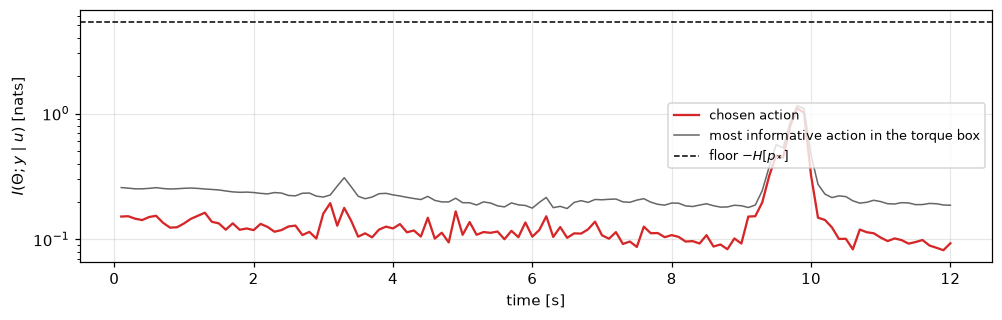

floor 5.37 nats; most informative action 0.176 to 1.154 nats; chosen action 0.082 to 1.103 nats; chosen / most informative: median 0.55


In [7]:
ep = episodes['with constraint (KKT β)']
agent = R.build_agent(s, None, nominal, R.joint_goal(R.joint_targets()[0], s))
box = np.stack(np.meshgrid(np.linspace(-1, 1, 11), np.linspace(-1, 1, 11)), -1).reshape(-1, 2)
agent.estimator.output_buffer = [np.r_[ep.xs[0, :2], 0, 0]]
best, chosen = [], []
for k in range(len(ep.actions)):
    best.append(max(agent.estimator.mutual_information(a) for a in box))
    chosen.append(agent.estimator.mutual_information(ep.actions[k]))
    agent.update(ep.ys[k], ep.actions[k])
best, chosen = np.array(best), np.array(chosen)
t = np.arange(1, len(best) + 1) * ep.dt

fig, ax = plt.subplots(figsize=(9, 2.8), layout='constrained')
ax.plot(t, chosen, color='C3', label='chosen action')
ax.plot(t, best, color='0.4', lw=1, label='most informative action in the torque box')
ax.axhline(ep.floor[0], color='k', ls='--', lw=1, label=r'floor $-H[p_*]$')
ax.set(yscale='log', xlabel='time [s]', ylabel=r'$I(\Theta; y \mid u)$ [nats]')
ax.legend(fontsize='small', loc='center right')
plt.show()
print(f'floor {ep.floor[0]:.2f} nats; most informative action {best.min():.3f} to {best.max():.3f} nats; '
      f'chosen action {chosen.min():.3f} to {chosen.max():.3f} nats; '
      f'chosen / most informative: median {np.median(chosen / best):.2f}')

The floor of 5.4 nats exceeds the most informative action in the torque box at every step, by a factor of 4.6 at the peak of 1.15 nats and of about 25 at the median of 0.21 nats. The KKT conditions therefore have no root, and β saturates at β_max = 50, which is the third case of the multiplier lemma in the paper. The chosen action delivers about half of the attainable information (median ratio 0.55), because the goal term still pulls it towards the target. Saturation follows from the floor, not from the task: $-H[p_*]$ measures how tight the goal is, while the attainable information measures how much the next output can still teach about the ARX coefficients.

## 5. The goal width moves the multiplier through its regimes

Scaling every goal standard deviation by a factor $\kappa$ lowers the floor by $D_y \ln\kappa = 4\ln\kappa$ nats. The cell runs the agent with the information constraint for several $\kappa$ (three seeds each) and records the mean multiplier, the fraction of steps on which the constraint is active, and the reaching performance. For comparison it also runs the agent without the constraint at the same goal widths.

In [8]:
kappas = (1.0, 2.0, 3.0, 3.5, 4.0, 5.0)
rows, t0 = [], time.perf_counter()
for kappa in kappas:
    sk = replace(s, pos_std=kappa * s.pos_std, vel_std=kappa * s.vel_std)
    for label, fixed_beta in VARIANTS.items():
        for seed in range(3):
            ep = R.run_seed(fixed_beta, seed, sk, truth)
            rows.append({'kappa': kappa, 'agent': label, 'floor': ep.floor[0], **R.summarise(ep, sk)})
print(f'{len(rows)} episodes in {time.perf_counter() - t0:.0f} s')
sweep = pd.DataFrame(rows)
sweep.groupby(['kappa', 'agent'], sort=False)[['floor', 'beta_mean', 'active', 'info_gain', 'reach_time',
                                               'reached', 'hold_error']].mean().round(3)

36 episodes in 62 s


floor  beta_mean  active  info_gain  \
kappa agent                                                             
1.0   without constraint (β = 0)  5.367      0.000   0.000      0.145   
      with constraint (KKT β)     5.367     50.000   1.000      0.151   
2.0   without constraint (β = 0)  2.595      0.000   0.000      0.137   
      with constraint (KKT β)     2.595     50.000   1.000      0.150   
3.0   without constraint (β = 0)  0.973      0.000   0.000      0.130   
      with constraint (KKT β)     0.973     50.000   1.000      0.156   
3.5   without constraint (β = 0)  0.356      0.000   0.000      0.129   
      with constraint (KKT β)     0.356     47.917   0.958      0.150   
4.0   without constraint (β = 0) -0.178      0.000   0.000      0.125   
      with constraint (KKT β)    -0.178      0.000   0.000      0.125   
5.0   without constraint (β = 0) -1.071      0.000   0.000      0.119   
      with constraint (KKT β)    -1.071      0.000   0.000      0.119   

                                  reach_time  reached  hold_error  
kappa agent                                                        
1.0   without constraint (β = 0)       1.333    1.000       1.140  
      with constraint (KKT β)          1.358    1.000       1.694  
2.0   without constraint (β = 0)       1.508    0.917       2.815  
      with constraint (KKT β)          1.908    0.750       6.140  
3.0   without constraint (β = 0)       1.825    1.000       3.228  
      with constraint (KKT β)          2.592    0.417      16.354  
3.5   without constraint (β = 0)       1.850    1.000       4.153  
      with constraint (KKT β)          2.742    0.500      21.735  
4.0   without constraint (β = 0)       1.900    1.000       5.591  
      with constraint (KKT β)          1.900    1.000       5.591  
5.0   without constraint (β = 0)       2.283    0.667      11.489  
      with constraint (KKT β)          2.283    0.667      11.489

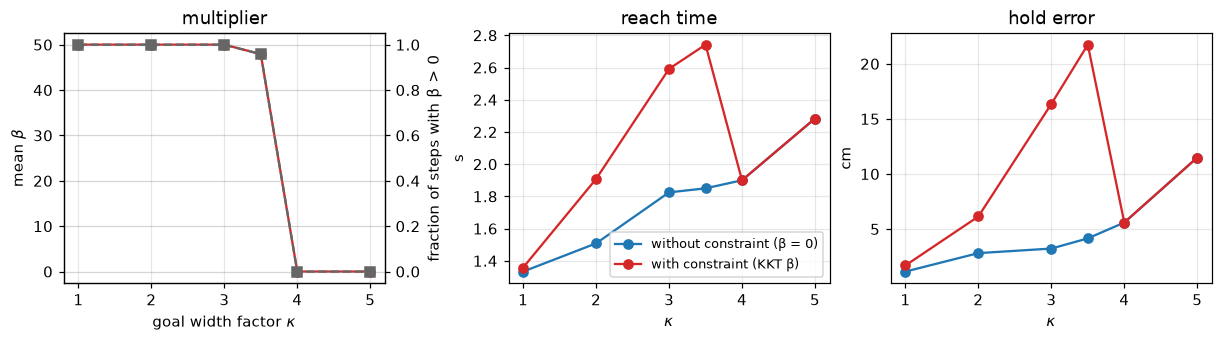

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3), layout='constrained')
for label in VARIANTS:
    g = sweep[sweep.agent == label].groupby('kappa')
    axs[1].plot(kappas, g.reach_time.mean(), 'o-', color=COLORS[label], label=label)
    axs[2].plot(kappas, g.hold_error.mean(), 'o-', color=COLORS[label])
g = sweep[sweep.agent == 'with constraint (KKT β)'].groupby('kappa')
axs[0].plot(kappas, g.beta_mean.mean(), 'o-', color=COLORS['with constraint (KKT β)'], label=r'mean $\beta$')
ax2 = axs[0].twinx()
ax2.plot(kappas, g.active.mean(), 's--', color='0.4', label='active fraction')
ax2.set(ylabel='fraction of steps with β > 0', ylim=(-0.05, 1.05))
axs[0].set(xlabel=r'goal width factor $\kappa$', ylabel=r'mean $\beta$', title='multiplier')
axs[1].set(xlabel=r'$\kappa$', ylabel='s', title='reach time')
axs[2].set(xlabel=r'$\kappa$', ylabel='cm', title='hold error')
axs[1].legend(fontsize='small')
plt.show()

Widening the goal lowers the floor from 5.4 nats at κ = 1 to −1.1 nats at κ = 5. The multiplier stays saturated down to κ = 3 (floor 0.97 nats), is active on 96 % of the steps at κ = 3.5 (floor 0.36 nats), and switches off from κ = 4 on, where the floor turns negative. The interior regime of the KKT conditions thus occupies a band of floors only a few tenths of a nat wide, between the information the agent collects anyway and the most it can collect. Before the floor reaches that band, saturated exploration costs the agent the targets: at κ = 3 it reaches 42 % of them and holds them at 16 cm, against 100 % and 3.2 cm without the constraint. Wider goals also slow the agent without the constraint, from 1.3 s at κ = 1 to 2.3 s at κ = 5, because the goal pulls more weakly.

## 6. Eight noise seeds

Both agents run the protocol with plant noise seeds 0 to 7, at the goal widths of Section 1. A fixed multiplier of $\beta = 10$ adds an intermediate epistemic weight. The table reports means and standard deviations over seeds.

In [10]:
N_SEEDS = 8
configs = {'without constraint (β = 0)': 0.0, 'fixed β = 10': 10.0, 'with constraint (KKT β)': None}
rows, t0 = [], time.perf_counter()
for label, fixed_beta in configs.items():
    for seed in range(N_SEEDS):
        ep = R.run_seed(fixed_beta, seed, s, truth)
        rows.append({'agent': label, 'seed': seed, **R.summarise(ep, s)})
print(f'{len(rows)} episodes in {time.perf_counter() - t0:.0f} s')
results = pd.DataFrame(rows)
results.drop(columns='seed').groupby('agent', sort=False).agg(['mean', 'std']).round(3)

24 episodes in 34 s


reach_time        reached      hold_error         \
                                 mean    std    mean  std       mean    std   
agent                                                                         
without constraint (β = 0)      1.344  0.162     1.0  0.0      1.188  0.200   
fixed β = 10                    1.316  0.130     1.0  0.0      1.334  0.186   
with constraint (KKT β)         1.475  0.214     1.0  0.0      3.253  2.634   

                           rms_torque        beta_mean      active       \
                                 mean    std      mean  std   mean  std   
agent                                                                     
without constraint (β = 0)      1.076  0.012       0.0  0.0    0.0  0.0   
fixed β = 10                    1.080  0.016      10.0  0.0    1.0  0.0   
with constraint (KKT β)         1.160  0.028      50.0  0.0    1.0  0.0   

                           info_gain        surprise        pred_rmse         \
                                mean    std     mean    std      mean    std   
agent                                                                          
without constraint (β = 0)     0.144  0.003   -3.872  0.078     0.207  0.011   
fixed β = 10                   0.145  0.004   -3.871  0.089     0.207  0.012   
with constraint (KKT β)        0.150  0.003   -3.901  0.155     0.216  0.017   

                           response_ratio         
                                     mean    std  
agent                                             
without constraint (β = 0)          0.845  0.022  
fixed β = 10                        0.842  0.013  
with constraint (KKT β)             0.893  0.033

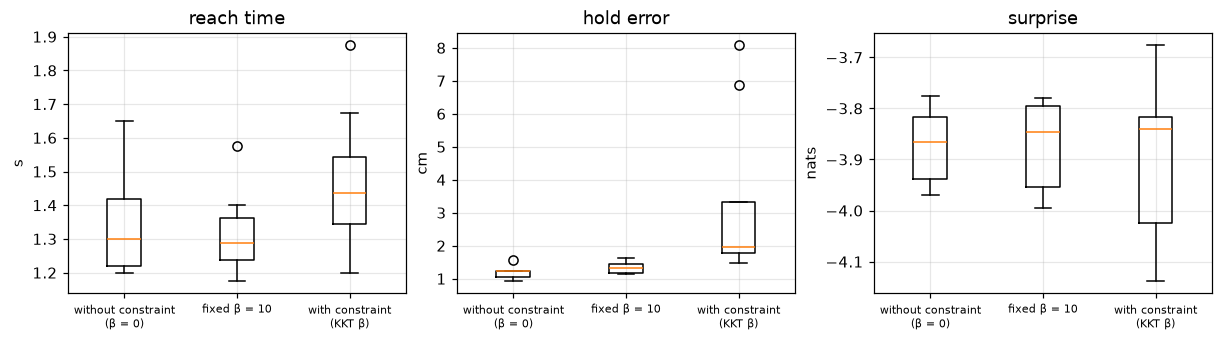

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(11, 3), layout='constrained')
labels = list(configs)
for ax, metric, unit in zip(axs, ('reach_time', 'hold_error', 'surprise'), ('s', 'cm', 'nats')):
    ax.boxplot([results.loc[results.agent == a, metric].to_numpy() for a in labels],
               tick_labels=[a.replace(' (', '\n(') for a in labels])
    ax.set(title=metric.replace('_', ' '), ylabel=unit)
    ax.tick_params(axis='x', labelsize=7)
plt.show()

Across eight seeds, all three agents reach every target. The fixed multiplier β = 10 performs like the agent without the constraint, with reach times of 1.32 and 1.34 s and holding errors of 1.33 and 1.19 cm. The saturated multiplier slows reaching to 1.48 s and degrades holding to 3.3 ± 2.6 cm, with two seeds above 6 cm. It raises the information collected per step by only 4 % (0.150 against 0.144 nats), and the surprise of the outputs changes by less than its spread over seeds. With the informative prior, the parameter information available to an action is too small to repay the probing.

## 7. Playground

Choose the multiplier mode, the goal widths, the prior weight, the planner and the noise seed, then press **Run Interact**. One episode takes a few seconds. The figure shows the end-effector path, the distance to the targets, and the multiplier with the information of the chosen actions.

The playground uses `interact_manual` because automatically re-run widgets stall `jupyter nbconvert --execute` on this machine.

In [12]:
from ipywidgets import interact_manual, widgets

@interact_manual(mode=widgets.Dropdown(options=['β = 0', 'KKT β', 'fixed β'], value='KKT β'),
                 fixed_beta=widgets.FloatLogSlider(value=10, base=10, min=-1, max=2, step=0.1),
                 kappa=widgets.FloatSlider(value=1.0, min=0.5, max=6.0, step=0.25),
                 prior_weight=widgets.FloatLogSlider(value=s.prior_weight, base=10, min=-2, max=0.5, step=0.1),
                 horizon=widgets.IntSlider(value=s.horizon, min=1, max=10),
                 n_iters=widgets.IntSlider(value=s.n_iters, min=1, max=4),
                 beta_max=widgets.FloatLogSlider(value=s.beta_max, base=10, min=0, max=3, step=0.1),
                 seed=widgets.IntSlider(value=0, min=0, max=20))
def playground(mode, fixed_beta, kappa, prior_weight, horizon, n_iters, beta_max, seed):
    sp = replace(s, pos_std=kappa * s.pos_std, vel_std=kappa * s.vel_std, prior_weight=prior_weight,
                 horizon=horizon, n_iters=n_iters, beta_max=beta_max)
    fb = {'β = 0': 0.0, 'KKT β': None, 'fixed β': fixed_beta}[mode]
    ep = R.run_seed(fb, seed, sp, truth)
    print(', '.join(f'{k} {v:.3g}' for k, v in R.summarise(ep, sp).items()))
    fig, axd = plt.subplot_mosaic([['arm', 'd'], ['arm', 'b']], figsize=(11, 4.6), layout='constrained')
    plot_workspace(axd['arm'], truth)
    for target in R.TARGETS:
        axd['arm'].plot(*target, '*', color='C2', ms=14, zorder=5)
    axd['arm'].plot(*ep.ee.T, color='C3', lw=1.5)
    t = np.arange(1, len(ep.actions) + 1) * ep.dt
    axd['d'].plot(t, 100 * ep.distance, color='C3')
    axd['d'].axhline(100 * R.REACH_TOL, color='k', lw=0.8, ls=':')
    axd['d'].set(yscale='log', ylabel='distance [cm]')
    axd['b'].plot(t, ep.beta, color='C3', label=r'$\beta$')
    axd['b'].set(ylabel=r'$\beta$', xlabel='time [s]')
    ax2 = axd['b'].twinx()
    ax2.plot(t, ep.info, color='0.4', lw=1, label='information')
    ax2.axhline(ep.floor[0], color='k', ls='--', lw=1, label='floor')
    ax2.set(ylabel='[nats]', yscale='log')
    ax2.legend(fontsize='x-small', loc='upper right')
    plt.show()

interactive(children=(Dropdown(description='mode', index=1, options=('β = 0', 'KKT β', 'fixed β'), value='KKT …

## 8. Takeaways


- **CBFE-ARX controls the arm in joint space with an informative prior.** With the default prior of `Agent.build`, it reaches no targets within 3 s. End-effector outputs are ruled out structurally, because the direction in which a torque moves the hand rotates with the shoulder angle. Encoders with 0.01 rad of noise instead of 0.001 rad still allow reaching, at a holding error of about 2 cm instead of 1.2 cm.
- **The information floor $-H[p_*]$ saturates the multiplier for any goal tight enough to reach.** At the default goal widths, the floor is 5.4 nats, while no action offers more than 1.2 nats. The KKT multiplier sits at β_max on every step.
- **The interior regime is a narrow band of floors.** Only the goal width moves the floor, and the multiplier switches from saturated to inactive between κ = 3.5 and 4. Before it gets there, saturated exploration loses the targets.
- **The epistemic drive does not pay in this setting.** The saturated agent gathers 4 % more information per step and holds the targets 2.7 times less precisely. The informative prior leaves little parameter information to gain, and the prediction errors that remain come from the model class.
- **The information measure has been corrected.** `MatrixNormalWishart.mutual_information` overstated $I(\Theta; y \mid u)$ by $(D_y/2)\ln\eta$, which grows with the data. The overstatement made the constraint look satisfied and switched β off. The version copied from the HARxI package carries the overstatement.